## Alright 

Now that we are done with the pre requisits and understanding of our upscaling concept, we not move on to the real deal of z-sampling.
That is instead of using pure maths to upscale an image/video we will train a CNN, we hope to overcome the cons of suing bi-lerp, and decrease the loss that occurs during it. 

## What V1 should accomplish

The main objective is to move from hand-designed reconstruction rules to reconstruction rules learned from examples.

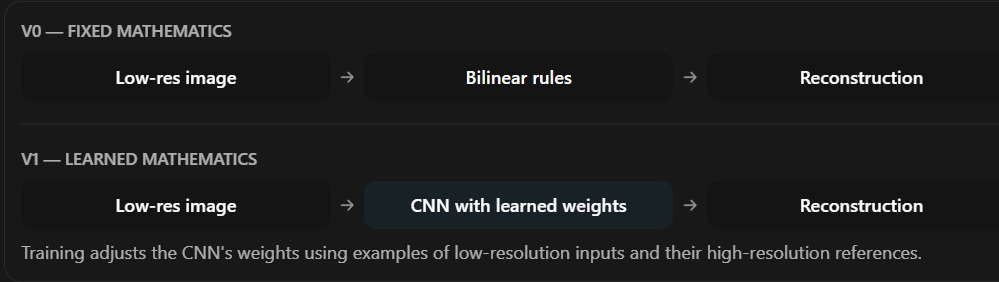

By the end, you should understand how a CNN works mathematically, implement a small network, train it using PyTorch, and evaluate it against your existing V0 methods.

We will also distinguish between improvements from training and improvements that merely come from changing the test data, degradation method or metric.



## Our V1 learning progression

Convolution and image kernels

Sliding windows, weighted sums, convolution vs cross-correlation, blur and edge detection, padding, stride and feature maps. Implement everything using NumPy.



From filters to neural networks

Neurons, weights, biases, activation functions and multiple channels. Understand what makes a filter learnable rather than manually designed.



### 1. **How networks learn**

    Forward propagation, loss functions, derivatives, the chain rule, gradients, backpropagation and gradient descent. Work through small numerical examples before training models.



### 2. **PyTorch fundamentals**

    Tensors, automatic differentiation, convolutional layers, optimizers and the training loop. Connect each operation to mathematics we previously implemented.



### 3. **Our first CNN super-resolution model**

    Prepare image pairs, define a small architecture, train it, observe failures and understand how it changes its weights.



### 4. **Controlled experiments**

    Compare CNN reconstruction against V0 bilinear and nearest neighbor on identical test inputs using PSNR, SSIM, visual differences, runtime and memory.

## L1 What even is convolution

Alright, remember we used a sliding window to calculate local SSIM. 
Where in we calculated the average,

for a 3x3 matrix:

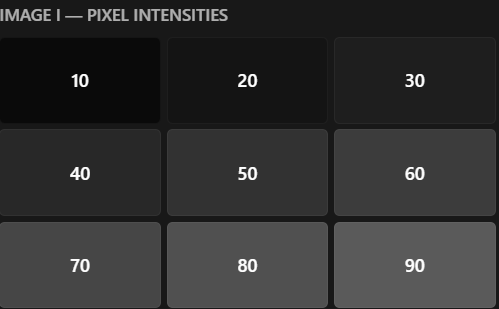

we do:
$$
\mu = \frac{10 + 20 + 30 + \cdots + 90}{9} = 50
$$

but, there is another way of doing this. 
Instead of adding all and dividing by 9. we can multiply value of each pixel by 1/9 and add them. 

$$
\mu = \sum_{i=0}^{2} \sum_{j=0}^{2} I[i,j] \cdot \frac{1}{9}
$$

we call it **weighted sum**

**kernels**

A kernel is a small matrix of weights that we apply to an image.

For example, this is a 3×3 averaging kernel:

$$
K = \frac{1}{9} 
\begin{bmatrix}
1 & 1 & 1 \\
1 & 1 & 1 \\
1 & 1 & 1
\end{bmatrix}
$$

Now we can:

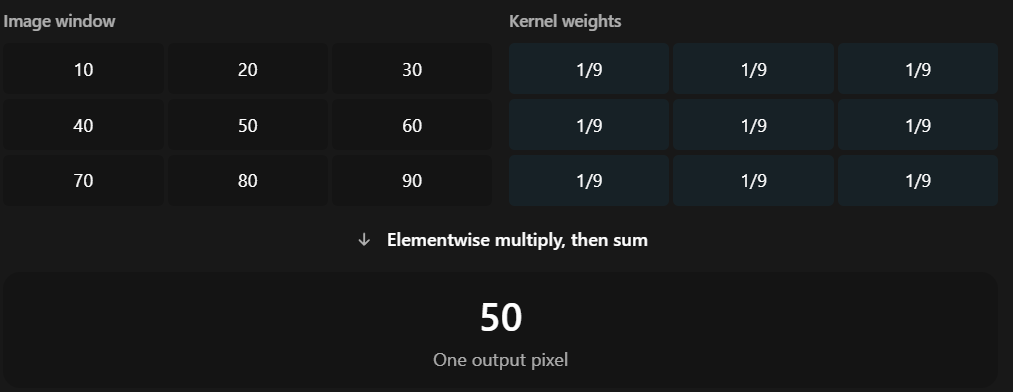

What makes this useful is that we can move that same kernel across an entire image.

At every position, it calculates a new weighted sum using the pixels underneath it.

That's the fundamental operation behind spatial filtering.

Let's describe the sliding operation precisely.
Suppose:
- $I$ is our input image.
- $K$ is our kernel.
- $Y$ is the resulting output image.

For a kernel of height $k_h$ and width $k_w$, define:
$$
Y[r,c] = \sum_{i=0}^{k_h-1} \sum_{j=0}^{k_w-1} I[r+i, c+j] \cdot K[i,j]
$$

Here, $r, c$ identify where the window starts in the image, while $i, j$ identify positions inside the kernel.

This formula says:
1. Select an image window.
2. Multiply its pixels by the corresponding kernel weights.
3. Sum the products.
4. Store the answer in the output.
5. Move to the next window.

For now, we're considering stride 1 and no padding, meaning the kernel only visits positions where it fits completely inside the image.


***Convolution generalizes the weighted-neighborhood idea by allowing us to choose the weights in a kernel.***

In [48]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

In [145]:
import numpy as np


def correlate2d_valid(
    image,
    kernel,
    padding: int = 0,
    stride: int = 1,
    pad_type: str = "constant"
):
    # 1. Validate parameters
    if not isinstance(stride, (int, np.integer)) or stride <= 0:
        raise ValueError("Stride must be a positive integer.")

    if not isinstance(padding, (int, np.integer)) or padding < 0:
        raise ValueError("Padding must be a non-negative integer.")

    if pad_type not in ("constant", "reflect", "edge"):
        raise ValueError(
            "Padding type must be 'constant', 'reflect', or 'edge'."
        )

    # 2. Convert inputs to float64
    image = np.asarray(image, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)

    if image.ndim != 2 or kernel.ndim != 2:
        raise ValueError("Image and kernel must be 2D arrays.")

    kh, kw = kernel.shape

    if kh == 0 or kw == 0:
        raise ValueError("Kernel cannot be empty.")

    # 3. Apply padding
    if pad_type == "constant":
        padded = np.pad(
            image,
            pad_width=padding,
            mode="constant",
            constant_values=0.0
        )
    else:
        padded = np.pad(
            image,
            pad_width=padding,
            mode=pad_type
        )

    pih, piw = padded.shape

    if pih < kh or piw < kw:
        raise ValueError(
            "Kernel dimensions exceed padded image dimensions."
        )

    # 4. Calculate output dimensions
    oh = (pih - kh) // stride + 1
    ow = (piw - kw) // stride + 1

    # 5. Allocate output
    output = np.zeros((oh, ow), dtype=np.float64)

    # 6. Perform cross-correlation
    for out_r, r in enumerate(range(0, pih - kh + 1, stride)):
        for out_c, c in enumerate(range(0, piw - kw + 1, stride)):

            window = padded[r:r + kh, c:c + kw]

            output[out_r, out_c] = np.sum(window * kernel)

    return output

In [137]:
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view


def correlate2d_valid_fast(
    image,
    kernel,
    padding: int = 0,
    stride: int = 1,
    pad_type: str = "constant",
):
  if stride <= 0:
    raise ValueError("stride must be a positive integer.")
  if padding < 0:
    raise ValueError("padding must be non-negative.")

  img = np.asarray(image, dtype=np.float64)
  ker = np.asarray(kernel, dtype=np.float64)

  kh, kw = ker.shape
  if kh == 0 or kw == 0:
    raise ValueError("Kernel must be non-empty.")

  if padding > 0:
    if pad_type == "constant":
      img = np.pad(img, pad_width=padding, mode=pad_type, constant_values=0.0)
    else:
      img = np.pad(img, pad_width=padding, mode=pad_type)

  ih, iw = img.shape
  if kh > ih or kw > iw:
    raise ValueError("Kernel dimensions cannot exceed padded image dimensions.")

  windows = sliding_window_view(img, (kh, kw))[::stride, ::stride]
  return np.einsum("ijkl,kl->ij", windows, ker, optimize=True)

Exploring 2D Correlation KernelsWhen sliding a $3 \times 3$ kernel $K$ over an input image $I$, the specific arrangement of weights determines what features are extracted or how pixel intensities are transformed. Below is an analysis of three fundamental kernel behaviors: Horizontal Edge Detection, Vertical Edge Detection, and Brightness Scaling (Identity).

In [36]:
I = np.array([
    [0, 0,  0,  0],
    [0, 0,  0, 90],
    [0, 0, 90, 90],
    [0, 90, 90, 90]
])

K = np.zeros((3, 3)) 
K[1][1] = 2

print(correlate2d_valid(I, K))

[[  0.   0.]
 [  0. 180.]]


2. Vertical Edge Detection (Horizontal Gradient)This kernel compares the center pixel directly against the pixel immediately to its left.$$K = \begin{bmatrix} 0 & 0 & 0 \\ -1 & 1 & 0 \\ 0 & 0 & 0 \end{bmatrix}$$How It WorksFormula: $\text{Output}[r, c] = I[r+1, c+1] - I[r+1, c]$Effect: By measuring differences along the horizontal axis, this kernel highlights vertical edges (transitions moving from left to right).Uniform regions produce $0$, while sharp vertical boundaries produce strong positive or negative spikes.

In [37]:
image = np.array([
    [10, 10, 10, 200, 200],
    [10, 10, 10, 200, 200],
    [10, 10, 10, 200, 200],
    [10, 10, 10, 200, 200],
    [10, 10, 10, 200, 200]
])

kernel = np.array([
    [0,  0, 0],
    [-1, 1, 0],
    [0,  0, 0]
])

result = correlate2d_valid(image, kernel)
print(result)

[[  0.   0. 190.]
 [  0.   0. 190.]
 [  0.   0. 190.]]


3. Horizontal Edge Detection (Vertical Gradient)This kernel compares the center pixel directly against the pixel immediately above it.$$K = \begin{bmatrix} 0 & -1 & 0 \\ 0 & 1 & 0 \\ 0 & 0 & 0 \end{bmatrix}$$How It WorksFormula: $\text{Output}[r, c] = I[r+1, c+1] - I[r, c+1]$Effect: Because it calculatles the difference aong the vertical axis, it ignores horizontal variations and highlights horizontal edges (transitions moving from top to bottom).If two vertically adjacent pixels have the same brightness, they cancel out to $0$.

In [38]:
I = np.array([
    [10, 10, 10 ],
    [10, 10, 10],
    [200, 200, 200 ],
])

K = np.array([
    [0 , -1 , 0],
    [0 , 1 , 0],
    [0, 0, 0]
])

result = correlate2d_valid(I,K)
result

array([[0.]])

These are called features, we can extract features from an image. We use different kinds of kernels to extract different kinds of features. The ones above were to detect different kinds of edges


Now To move ahead, we should try to do these on an actual image.

Our kernels are still too simple, we just have 1 stride and no padding, but well get on with that later


## Feature Maps
Suppose we have an image $I$ and three kernels:
- $K_1$: Averaging filter — captures local brightness.
- $K_2$: Horizontal intensity differences — responds to vertical edges.
- $K_3$: Vertical intensity differences — responds to horizontal edges.

We apply each kernel independently:

$$F_1 = I \star K_1$$

$$F_2 = I \star K_2$$

$$F_3 = I \star K_3$$

Here, $\star$ represents cross-correlation.

Each resulting matrix is called a Feature Map

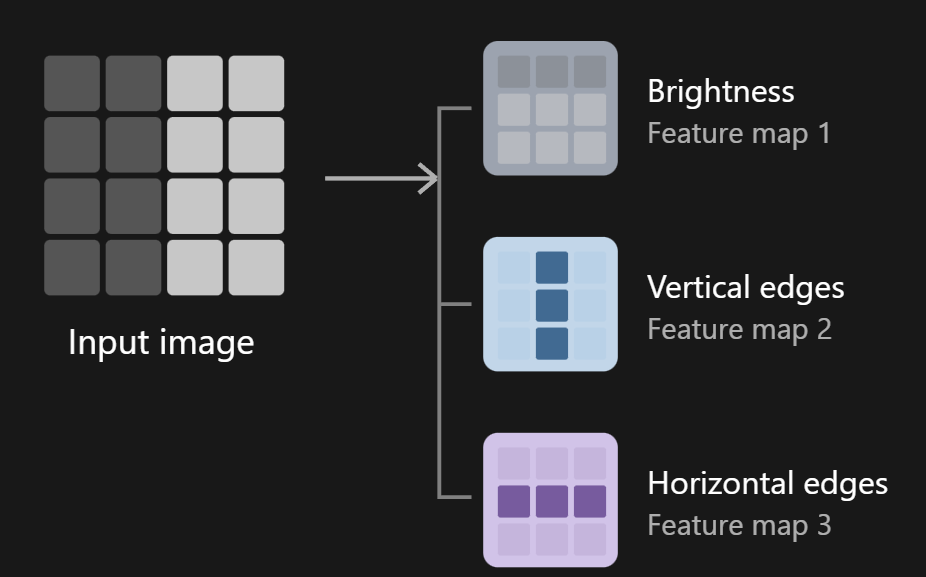

In [80]:
# Alright lets try it on a small image

avg_kernel = np.ones((3, 3)) / 9

vertical_edge_kernel = np.array([
    [0, 0, 0],
    [-1, 1, 0],
    [0, 0, 0]
])

horizontal_edge_kernel = np.array([
    [0, -1, 0],
    [0,  1, 0],
    [0,  0, 0]
])

diagonal_1 = np.array([
    [1, 0, 0],
    [0, 0, 0],
    [0, 0, -1]
])

doagonal_2 = np.array([
    [0, 0, 1],
    [0,  0, 0],
    [-1,  0, 0]
])

In [81]:
image = Image.open("ginue-pigs/goddamn.png").convert("L")
img = np.asarray(image,dtype=np.float64)


In [82]:
img.shape

(1024, 1024)

In [138]:
avg_f = correlate2d_valid_fast(img,avg_kernel,1,1,"edge")
hor_f = correlate2d_valid_fast(img,horizontal_edge_kernel,1,1,"edge")
ver_f = correlate2d_valid_fast(img,vertical_edge_kernel,1,1,"reflect")

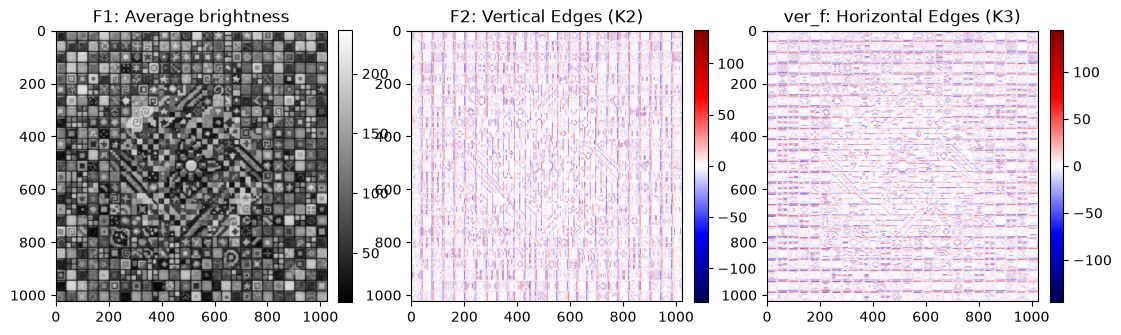

In [139]:
fig,axes = plt.subplots(1,3,figsize=(13,4))

img1 = axes[0].imshow(avg_f,cmap="gray")
axes[0].set_title("F1: Average brightness")
plt.colorbar(img1,ax=axes[0],fraction=0.046,pad=0.04)

max_abs_2 = np.max(np.abs(ver_f))
img2 = axes[1].imshow(ver_f,cmap="seismic",vmin=-max_abs_2, vmax=max_abs_2)
axes[1].set_title("F2: Vertical Edges (K2)")
plt.colorbar(img2, ax=axes[1], fraction=0.046, pad=0.04)

max_abs_3 = np.max(np.abs(hor_f))
img3 = axes[2].imshow(hor_f, cmap="seismic", vmin=-max_abs_3, vmax=max_abs_3)
axes[2].set_title("ver_f: Horizontal Edges (K3)")
plt.colorbar(img3, ax=axes[2], fraction=0.046, pad=0.04)


In [132]:
features = np.stack([
    avg_f,
    ver_f,
    hor_f
], axis=-1)

print(features.shape)
# (1022, 1022, 3)

(1024, 1024, 3)


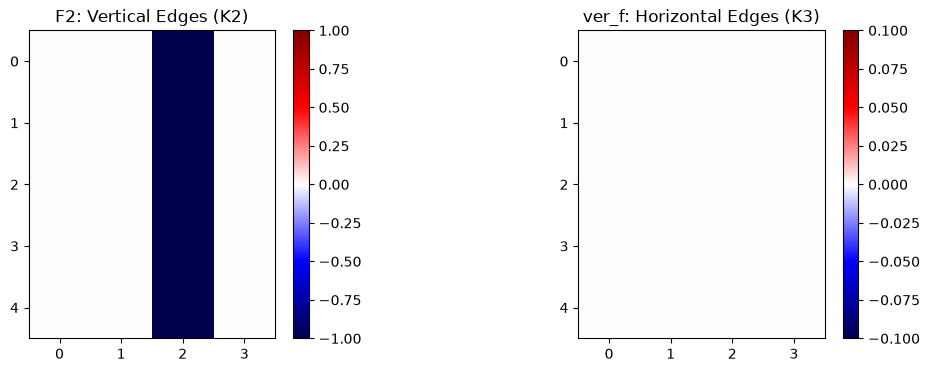

In [140]:
bw = np.array(([1,1,0,0],[1,1,0,0],[1,1,0,0],[1,1,0,0],[1,1,0,0]),dtype=np.float64)

feat = correlate2d_valid_fast(bw,horizontal_edge_kernel,1,1,"edge")
feat2 = correlate2d_valid_fast(bw,vertical_edge_kernel,1,1,"edge")

fig,axes = plt.subplots(1,2,figsize=(13,4))

max_abs_2 = np.max(np.abs(feat2))
img2 = axes[0].imshow(feat2,cmap="seismic",vmin=-max_abs_2, vmax=max_abs_2)
axes[0].set_title("F2: Vertical Edges (K2)")
plt.colorbar(img2, ax=axes[0], fraction=0.046, pad=0.04)

max_abs_3 = np.max(np.abs(feat))
img3 = axes[1].imshow(feat, cmap="seismic", vmin=-max_abs_3, vmax=max_abs_3)
axes[1].set_title("ver_f: Horizontal Edges (K3)")
plt.colorbar(img3, ax=axes[1], fraction=0.046, pad=0.04)

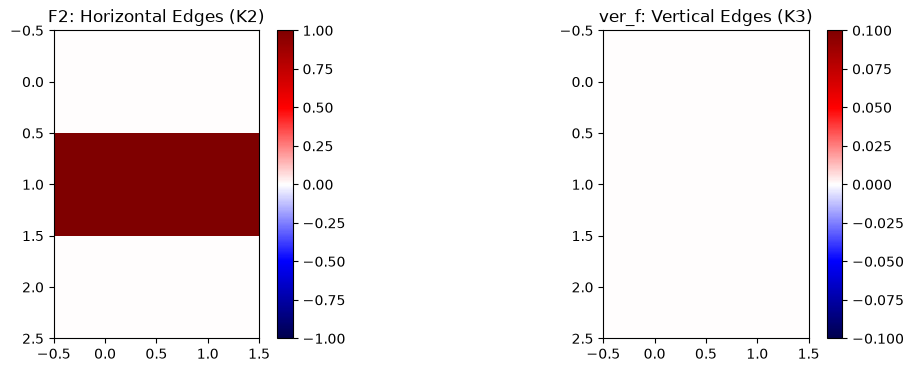

In [136]:
bw = np.array(([0,0,0,0],[0,0,0,0],[1,1,1,1],[1,1,1,1],[1,1,1,1]),dtype=np.float64)

feat = correlate2d_valid_fast(bw,horizontal_edge_kernel,"constant")
feat2 = correlate2d_valid_fast(bw,vertical_edge_kernel,"constant")

fig,axes = plt.subplots(1,2,figsize=(13,4))

max_abs_2 = np.max(np.abs(feat))
img2 = axes[0].imshow(feat,cmap="seismic",vmin=-max_abs_2, vmax=max_abs_2)
axes[0].set_title("F2: Horizontal Edges (K2)")
plt.colorbar(img2, ax=axes[0], fraction=0.046, pad=0.04)

max_abs_3 = np.max(np.abs(feat2))
img3 = axes[1].imshow(feat2, cmap="seismic", vmin=-max_abs_3, vmax=max_abs_3)
axes[1].set_title("ver_f: Vertical Edges (K3)")
plt.colorbar(img3, ax=axes[1], fraction=0.046, pad=0.04)

## Paddin and Stride

1. Padding

    Padding means adding extra pixels around an image before performing the convolution operation.
    The simplest approach is zero padding, where we surround the image with zeros.

    The general formula
    The general formula
    If we add $P$ pixels of padding on both sides:

    $$\boxed{H_{out} = H + 2P - K_h + 1}$$

    And similarly:

    $$W_{out} = W + 2P - K_w + 1$$

2. Stride
    Until now, our kernel has moved one pixel at a time.

    That's called stride = 1.

    What happens if we increase it to 2?

    Instead of processing every possible position, our kernel jumps two pixels between starting positions.

## Combining Padding and Stride

Now we can express everything in one formula:

$$\boxed{H_{out} = \left\lfloor \frac{H + 2P - K_h}{S} \right\rfloor + 1}$$

Where:
- $H$ = image height
- $P$ = padding on each side
- $K_h$ = kernel height
- $S$ = stride
- $\lfloor\cdot\rfloor$ = floor, meaning round down to the nearest integer

The corresponding width formula uses $W$ and $K_w$:

$$W_{out} = \left\lfloor \frac{W + 2P - K_w}{S} \right\rfloor + 1$$

Let's look at a $5\times 5$ image with a $3\times 3$ kernel:

| Padding | Stride | Output shape |
| :---: | :---: | :---: |
| 0 | 1 | $3\times 3$ |
| 1 | 1 | $5\times 5$ |
| 0 | 2 | $2\times 2$ |
| 1 | 2 | $3\times 3$ |

Notice how padding and stride can independently affect the output dimensions. This is particularly useful in CNNs, where we sometimes want to preserve spatial resolution and sometimes want to reduce it.

In [106]:
# we have now improved our implementation of convulution to inlcude padding and stride,

I = np.array([
    [1, 2, 3],
    [4, 5, 6],
    [7, 8, 9]
])

K = np.ones((3, 3))

In [143]:
result = correlate2d_valid(
    I, K, padding=1, stride=1,pad_type="constant"
)

print(result)
print(result.shape)

[[12. 21. 16.]
 [27. 45. 33.]
 [24. 39. 28.]]
(3, 3)


## Types of Paddings

The interesting part is that the same kernel can produce different outputs depending on how we pad the image.

This matters in CNN-based super-resolution because artificial boundaries can influence reconstructed pixels near the edges.

1. Padding
2. Reflect
3. Replicate

In [146]:
for mode in ["constant", "reflect", "edge"]:
    result = correlate2d_valid(
        I, K,
        padding=1,
        stride=1,
        pad_type=mode
    )
    print(mode, result[0, 0])

constant 12.0
reflect 33.0
edge 21.0


| Padding method | Top-left output | Behavior |
| :--- | :---: | :--- |
| Constant (zero) | 12 | Introduces artificial zeros |
| Reflect | 33 | Mirrors values across the boundary |
| Edge (replicate) | 21 | Repeats the nearest border pixels |

## Receptive Fields

Now we're getting closer to actual CNN architecture.

Until now, we've applied a single kernel to an image.

But what happens when we stack convolutional layers?

The first layer looks at 3×3 neighborhoods of the original image.

The second layer looks at 3×3 neighborhoods of the first layer's output, not directly at the original image.

And here's the interesting part:

Each pixel in the second layer can indirectly depend on a region of the original image that's larger than 3×3.

We call this region the receptive field.

A receptive field tells us how much of the original input can influence a particular output value.